# Avaliação de Modelos e Classificação de Renda — Adult Census Income
**Programa de Pós-Graduação em Ciência da Computação (PPGCC) — Aprendizado de Máquina**

---

### Visão Geral e Objetivo
Este notebook implementa o pipeline estruturado de modelagem preditiva e explicabilidade para o dataset **Adult Census Income** (UCI / US Census Bureau 1994).
A tarefa consiste em uma **classificação binária supervisionada** para predizer se a renda anual de um indivíduo excede US$ 50 mil (`> 50 mil`) ou não (`≤ 50 mil`) a partir de atributos sociodemográficos, educacionais e ocupacionais.

### Sumário da Estrutura Experimental
1. **Configuração e Carregamento:** Importação de dependências e integração com o dicionário semântico (`traducao.py`).
2. **Tratamento de Dados e Higienização Metodológica:**
   - Tratamento de valores ausentes (`?` / `Não informado`) e remoção de duplicatas.
   - Remoção fundamentada de ruído amostral (`peso_amostral` / `fnlwgt`).
   - Resolução da redundância de escolaridade (`escolaridade` textual vs. ordinal `escolaridade_num`).
   - Codificação de atributos (*One-Hot Encoding*) e codificação determinística da variável-alvo.
3. **Protocolo Experimental:** Partição Treino (70%) / Teste (30%) com estratificação e validação cruzada 5-fold estritamente no treino.
4. **Experimento 1 (Ablação de Features):** Impacto empírico da remoção de `peso_amostral` e variáveis redundantes.
5. **Experimento 2 (Balanceamento de Classes):** Desempenho comparativo entre modelo padrão vs. ponderação balanceada (`class_weight='balanced'`).
6. **Experimento 3 (Otimização e Pré-Poda Clássica):** Controle de complexidade via parada antecipada (`max_depth`, `min_samples_leaf`, `min_samples_split`, `class_weight`) com Curva de Validação e `GridSearchCV`, selecionando pela acurácia (objetivo da atividade) e registrando F1, revocação e ROC-AUC.
7. **Avaliação Definitiva no Conjunto de Teste:** Métricas multi-dimensionais (Acurácia, Balanced Accuracy, Precision, Recall, F1, ROC-AUC), Matriz de Confusão e Importância de Variáveis.
8. **Persistência do Modelo:** Serialização e salvamento do estimador final e metadados em disco (`modelos/`).
9. **Extração de Regras e Interpretabilidade (XAI):** Extração auditável e correta dos perfis de Alta Renda e Baixa Renda em linguagem natural.


---

> **Revisão (26/10/2026).** Este notebook corresponde ao `treinamento.ipynb` original, com as seguintes correções: (i) a grade de busca passou a cobrir a profundidade apontada pela curva de validação (4 a 12) e o parâmetro `class_weight`, que o Experimento 2 recomendava mas a grade não incluía; (ii) a seleção passou a usar a **acurácia**, que é o objetivo da atividade, com as demais métricas registradas lado a lado; (iii) a interpretação das regras deixou de depender de um limiar fixo no código e passou a ordenar os perfis pelo número de pessoas cobertas, não só pela pureza; (iv) condições redundantes nas regras (vários cortes no mesmo atributo) são simplificadas; (v) as conclusões foram reescritas para refletir os números obtidos. Os experimentos com outras famílias de modelos e estratégias de busca estão no notebook `04_experimentos.ipynb`.


## 1. Configuração do Ambiente e Carregamento dos Dados

Importamos as bibliotecas necessárias para manipulação vetorial, modelagem com Árvores de Decisão (Scikit-Learn), serialização com `joblib` e visualização de dados. Fixamos a semente aleatória (`SEED = 42`) para garantir total reprodutibilidade dos experimentos.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, validation_curve
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# Módulo local de tradução semântica do dataset
from traducao import traduzir_dataframe, dicionario_dados

# Configurações visuais elegantes
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.autolayout"] = True
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

SEED = 42
print("Ambiente configurado com sucesso. Seed fixada em:", SEED)


Ambiente configurado com sucesso. Seed fixada em: 42


In [2]:
# Carregamento do dataset original
df_raw = pd.read_csv("adult.csv")
print(f"Dimensões originais: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")

# Tradução padronizada dos identificadores e categorias
df = traduzir_dataframe(df_raw, ausente=np.nan)
df.head(5)


Dimensões originais: 32561 linhas e 15 colunas.


,idade,classe_trabalho,peso_amostral,escolaridade,escolaridade_num,estado_civil,ocupacao,relacao_familiar,raca,sexo,ganho_capital,perda_capital,horas_semana,pais_origem,renda
0,90,NaN,77053,Ensino médio completo,9,Viúvo(a),NaN,Sem vínculo familiar,Branca,Feminino,0,4356,40,Estados Unidos,≤ 50 mil
1,82,Setor privado,132870,Ensino médio completo,9,Viúvo(a),Executivo/gerencial,Sem vínculo familiar,Branca,Feminino,0,4356,18,Estados Unidos,≤ 50 mil
2,66,NaN,186061,Superior incompleto,10,Viúvo(a),NaN,Não casado(a),Negra,Feminino,0,4356,40,Estados Unidos,≤ 50 mil
3,54,Setor privado,140359,7ª a 8ª série,4,Divorciado(a),Operação de máquinas/inspeção,Não casado(a),Branca,Feminino,0,3900,40,Estados Unidos,≤ 50 mil
4,41,Setor privado,264663,Superior incompleto,10,Separado(a),Profissional especializado,Filho(a),Branca,Feminino,0,3900,40,Estados Unidos,≤ 50 mil


## 2. Tratamento dos Dados e Higienização Metodológica

Nesta seção, realizamos a limpeza dos dados e tomamos decisões fundamentadas de engenharia de atributos:
1. **Remoção de Duplicatas:** Eliminação de 24 registros 100% idênticos em todas as colunas.
2. **Tratamento de Valores Ausentes:** Identificação e descarte das linhas com valores nulos (concentrados em `classe_trabalho`, `ocupacao` e `pais_origem`).
3. **Descarte de Atributos Espúrios (`peso_amostral` / `fnlwgt`):** O peso amostral é uma métrica populacional do US Census Bureau que estima quantas pessoas cada linha representa na população geral. Ele não descreve atributos intrínsecos do indivíduo (como competência ou qualificação) e, se mantido, induz a árvore a memorizar ruídos e cortes artificiais.
4. **Resolução de Redundância (`escolaridade` vs. `escolaridade_num`):** `escolaridade_num` já é a codificação ordinal exata (1 a 16) de `escolaridade`. Manter ambas gera 15 colunas *dummy* desnecessárias e multicolinearidade perfeita. Manteremos apenas `escolaridade_num`.


In [3]:
# 1. Remoção de duplicatas
n_duplicadas = df.duplicated().sum()
if n_duplicadas > 0:
    df.drop_duplicates(inplace=True)
    print(f"Removidas {n_duplicadas} linhas duplicadas.")

# 2. Diagnóstico e remoção de valores ausentes
n_nulos = df.isnull().sum().sum()
print(f"Total de valores ausentes identificados: {n_nulos}")
df_limpo = df.dropna().copy()
print(f"Base após remoção de ausentes: {len(df_limpo)} linhas (redução de {len(df_raw) - len(df_limpo)} linhas / ~{(len(df_raw) - len(df_limpo))/len(df_raw)*100:.2f}%).")

# 3. Codificação explícita e determinística da variável alvo
# 0: <= 50 mil (Baixa Renda), 1: > 50 mil (Alta Renda)
y = (df_limpo["renda"] == "> 50 mil").astype(int)
nomes_classes = ["≤ 50 mil", "> 50 mil"]

print("\nDistribuição da variável-alvo:")
contagem_y = y.value_counts(normalize=True) * 100
print(f"  Classe 0 (≤ 50 mil): {contagem_y[0]:.2f}% ({y.value_counts()[0]} amostras)")
print(f"  Classe 1 (> 50 mil): {contagem_y[1]:.2f}% ({y.value_counts()[1]} amostras)")


Removidas 24 linhas duplicadas.
Total de valores ausentes identificados: 4261
Base após remoção de ausentes: 30139 linhas (redução de 2422 linhas / ~7.44%).

Distribuição da variável-alvo:
  Classe 0 (≤ 50 mil): 75.10% (22633 amostras)
  Classe 1 (> 50 mil): 24.90% (7506 amostras)


In [4]:
# Preparação das matrizes de atributos:
# Configuração 1 (Limpa/Higienizada): sem 'peso_amostral' e sem a coluna textual redundante 'escolaridade'
X_limpo = df_limpo.drop(columns=["renda", "peso_amostral", "escolaridade"])
X_limpo = pd.get_dummies(X_limpo, drop_first=True)

# Configuração 2 (Com peso_amostral e redundância): para fins do Estudo de Ablação no Experimento 1
X_com_tudo = df_limpo.drop(columns=["renda"])
X_com_tudo = pd.get_dummies(X_com_tudo, drop_first=True)

print(f"Dimensionalidade X_limpo (Recomendado): {X_limpo.shape[1]} atributos.")
print(f"Dimensionalidade X_com_tudo (Com ruído): {X_com_tudo.shape[1]} atributos.")


Dimensionalidade X_limpo (Recomendado): 80 atributos.
Dimensionalidade X_com_tudo (Com ruído): 96 atributos.


## 3. Protocolo Experimental e Partição dos Dados

Para evitar **Vazamento de Dados (*Data Leakage*)**, o conjunto de teste (30%) é separado logo no início e mantido completamente intocado.
Toda a validação, teste de hipóteses e ajuste de hiperparâmetros será realizada via **Validação Cruzada Estratificada 5-Fold** restrita ao conjunto de treinamento.


In [5]:
# Divisão Estratificada 70% Treino / 30% Teste
X_train, X_test, y_train, y_test = train_test_split(
    X_limpo,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

# Separação correspondente para a base completa (estudo de ablação)
X_train_tudo, X_test_tudo, _, _ = train_test_split(
    X_com_tudo,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED
)

cv_estrategia = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Amostras de Treino: {X_train.shape[0]}")
print(f"Amostras de Teste:  {X_test.shape[0]}")


Amostras de Treino: 21097
Amostras de Teste:  9042


In [6]:
# Função utilitária para calcular métricas completas via Validação Cruzada
def avaliar_cv(modelo, X, y, cv):
    metricas = {
        "acuracia": "accuracy",
        "acuracia_bal": "balanced_accuracy",
        "precisao": "precision",
        "revocacao": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }
    scores = cross_validate(modelo, X, y, cv=cv, scoring=metricas)
    resumo = {m: scores[f"test_{m}"].mean() for m in metricas}
    resumo_std = {f"{m}_std": scores[f"test_{m}"].std() for m in metricas}
    return {**resumo, **resumo_std}


## 4. Experimento 1: Estudo de Ablação — Impacto de `peso_amostral` e Redundâncias

Avaliamos a hipótese levantada na exploração inicial:
- **Modelo A (Com tudo):** Mantém `peso_amostral` e 15 dummies de `escolaridade` + `escolaridade_num`.
- **Modelo B (Higienizado):** Remove `peso_amostral` e mantém apenas `escolaridade_num`.

Testamos ambos com uma Árvore de Decisão padrão com controle de profundidade (`max_depth=5`) na validação cruzada.


In [7]:
arvore_base = DecisionTreeClassifier(max_depth=5, random_state=SEED)

res_tudo = avaliar_cv(arvore_base, X_train_tudo, y_train, cv_estrategia)
res_limpo = avaliar_cv(arvore_base, X_train, y_train, cv_estrategia)

tabela_ablação = pd.DataFrame([
    {
        "Configuração": "Modelo A (Com peso_amostral e redundâncias)",
        "Nº Features": X_train_tudo.shape[1],
        "Acurácia": f"{res_tudo['acuracia']*100:.2f}%",
        "Acurácia Balanceada": f"{res_tudo['acuracia_bal']*100:.2f}%",
        "F1-Score": f"{res_tudo['f1']*100:.2f}%",
        "ROC-AUC": f"{res_tudo['roc_auc']*100:.2f}%"
    },
    {
        "Configuração": "Modelo B (Higienizado - sem ruído)",
        "Nº Features": X_train.shape[1],
        "Acurácia": f"{res_limpo['acuracia']*100:.2f}%",
        "Acurácia Balanceada": f"{res_limpo['acuracia_bal']*100:.2f}%",
        "F1-Score": f"{res_limpo['f1']*100:.2f}%",
        "ROC-AUC": f"{res_limpo['roc_auc']*100:.2f}%"
    }
])

display(tabela_ablação)


,Configuração,Nº Features,Acurácia,Acurácia Balanceada,F1-Score,ROC-AUC
0,Modelo A (Com peso_amostral e redundâncias),96,83.95%,72.68%,60.91%,87.91%
1,Modelo B (Higienizado - sem ruído),80,83.96%,72.71%,60.94%,87.97%


**Discussão:**
A diferença entre as duas configurações é de 0,01 ponto percentual de acurácia e menos de 0,1 ponto de ROC-AUC, dentro do desvio padrão entre folds. A remoção de `peso_amostral` e da redundância textual de `escolaridade` **não altera o desempenho** da árvore; ela se justifica pela semântica (o peso amostral descreve o desenho da pesquisa, não a pessoa) e pela interpretabilidade das regras, que deixam de conter cortes em um atributo sem significado individual.

## 5. Experimento 2: Efeito do Balanceamento de Classes

O dataset Adult apresenta proporção de aproximadamente 3:1 a favor da classe de menor renda (`≤ 50 mil`). Em modelos sem ajuste, o algoritmo tende a favorecer a classe majoritária, prejudicando a **Revocação** da classe de Alta Renda (`> 50 mil`).

Comparamos:
1. **Sem Balanceamento:** `class_weight=None` (prioriza acurácia global bruta).
2. **Com Balanceamento:** `class_weight='balanced'` (penaliza mais os erros cometidos na classe minoritária).


In [8]:
arvore_padrao = DecisionTreeClassifier(max_depth=5, random_state=SEED)
arvore_balanceada = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=SEED)

res_padrao = avaliar_cv(arvore_padrao, X_train, y_train, cv_estrategia)
res_balanceada = avaliar_cv(arvore_balanceada, X_train, y_train, cv_estrategia)

tabela_bal = pd.DataFrame([
    {
        "Abordagem": "Padrão (class_weight=None)",
        "Acurácia Global": f"{res_padrao['acuracia']*100:.2f}%",
        "Acurácia Balanceada": f"{res_padrao['acuracia_bal']*100:.2f}%",
        "Precisão (>50K)": f"{res_padrao['precisao']*100:.2f}%",
        "Revocação (>50K)": f"{res_padrao['revocacao']*100:.2f}%",
        "F1-Score (>50K)": f"{res_padrao['f1']*100:.2f}%",
        "ROC-AUC": f"{res_padrao['roc_auc']*100:.2f}%"
    },
    {
        "Abordagem": "Balanceada (class_weight='balanced')",
        "Acurácia Global": f"{res_balanceada['acuracia']*100:.2f}%",
        "Acurácia Balanceada": f"{res_balanceada['acuracia_bal']*100:.2f}%",
        "Precisão (>50K)": f"{res_balanceada['precisao']*100:.2f}%",
        "Revocação (>50K)": f"{res_balanceada['revocacao']*100:.2f}%",
        "F1-Score (>50K)": f"{res_balanceada['f1']*100:.2f}%",
        "ROC-AUC": f"{res_balanceada['roc_auc']*100:.2f}%"
    }
])

display(tabela_bal)


,Abordagem,Acurácia Global,Acurácia Balanceada,Precisão (>50K),Revocação (>50K),F1-Score (>50K),ROC-AUC
0,Padrão (class_weight=None),83.96%,72.71%,77.42%,50.29%,60.94%,87.97%
1,Balanceada (class_weight='balanced'),77.81%,80.51%,53.43%,85.88%,65.86%,88.75%


**Interpretação do Trade-off:**
- O modelo com **`class_weight='balanced'`** aumenta a **Revocação** da classe `> 50 mil` de cerca de 50% para cerca de 86%, mas reduz a precisão e **derruba a acurácia global em cerca de 6 pontos percentuais**.
- Como o objetivo da atividade é maximizar o acerto, o balanceamento entra na busca em grade abaixo como mais um hiperparâmetro, e a seleção final decide pela acurácia. Em aplicações em que o custo de não detectar a alta renda é elevado, a variante balanceada é a indicada.


## 6. Experimento 3: Otimização de Hiperparâmetros e Pré-Poda Clássica (*Pre-Pruning*)

Em Aprendizado de Máquina, a **Pré-Poda (*Pre-Pruning*)** consiste em impor critérios de parada antecipada durante o crescimento da árvore, impedindo que ela crie ramos excessivamente específicos que memorizam o ruído do treino (*overfitting*).

### Hiperparâmetros Fundamentais Avaliados:
* **`max_depth` (Profundidade Máxima):** Controla o número máximo de níveis de decisão da raiz até qualquer folha.
* **`min_samples_leaf` (Mínimo de Amostras por Folha):** Exige que cada nó-folha contenha um número mínimo de instâncias, evitando folhas com poucos casos anômalos.
* **`min_samples_split` (Mínimo de Amostras para Divisão):** Número mínimo de observações necessárias para permitir a divisão de um nó interno.

* **`class_weight` (Peso das Classes):** `None` ou `'balanced'`, para verificar se o balanceamento do Experimento 2 sobrevive à seleção pela acurácia.

### 6.1 Curva de Validação: Impacto de `max_depth` no Trade-off Viés-Variância

A curva é calculada para a acurácia e para o F1, com a mesma validação cruzada. Ela orienta a faixa de profundidades da grade da seção 6.2.


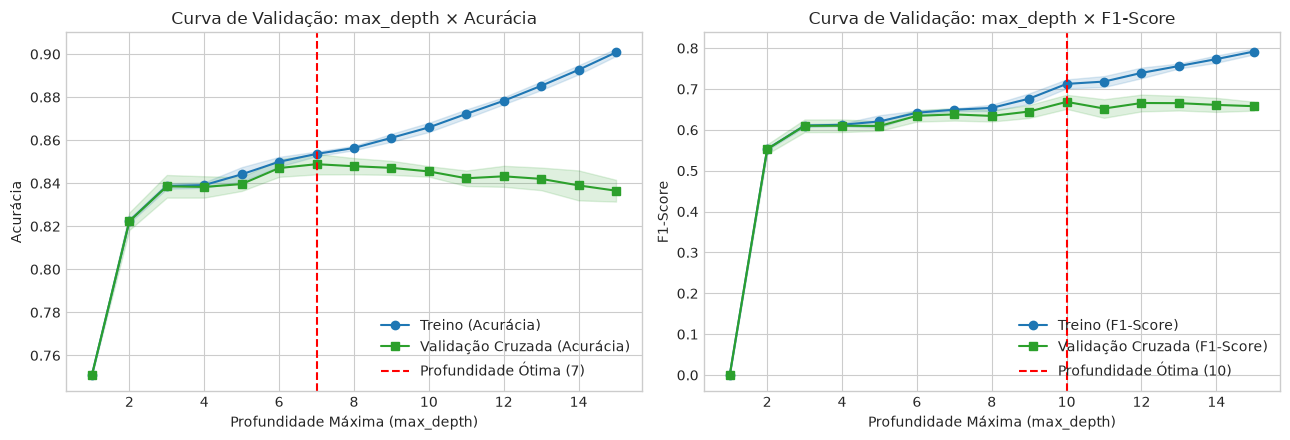

Profundidade com maior acurácia na validação cruzada: 7 (84.88%)
Profundidade com maior F1 na validação cruzada: 10 (66.85%)


In [9]:
# 1. Curva de Validação para analisar o efeito da Profundidade (max_depth), em acurácia e F1
profundidades = np.arange(1, 16)
curvas = {}
for metrica in ["accuracy", "f1"]:
    train_scores, val_scores = validation_curve(
        DecisionTreeClassifier(random_state=SEED), X_train, y_train,
        param_name="max_depth", param_range=profundidades, cv=cv_estrategia, scoring=metrica, n_jobs=-1,
    )
    curvas[metrica] = (train_scores.mean(axis=1), train_scores.std(axis=1),
                       val_scores.mean(axis=1), val_scores.std(axis=1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (metrica, nome) in zip(axes, [("accuracy", "Acurácia"), ("f1", "F1-Score")]):
    train_mean, train_std, val_mean, val_std = curvas[metrica]
    ax.plot(profundidades, train_mean, marker="o", label=f"Treino ({nome})", color="#1f77b4")
    ax.fill_between(profundidades, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#1f77b4")
    ax.plot(profundidades, val_mean, marker="s", label=f"Validação Cruzada ({nome})", color="#2ca02c")
    ax.fill_between(profundidades, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#2ca02c")
    melhor = profundidades[np.argmax(val_mean)]
    ax.axvline(melhor, color="red", linestyle="--", label=f"Profundidade Ótima ({melhor})")
    ax.set_title(f"Curva de Validação: max_depth × {nome}")
    ax.set_xlabel("Profundidade Máxima (max_depth)")
    ax.set_ylabel(nome)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

melhor_prof_acc = profundidades[np.argmax(curvas["accuracy"][2])]
melhor_prof_f1 = profundidades[np.argmax(curvas["f1"][2])]
print(f"Profundidade com maior acurácia na validação cruzada: {melhor_prof_acc} ({np.max(curvas['accuracy'][2])*100:.2f}%)")
print(f"Profundidade com maior F1 na validação cruzada: {melhor_prof_f1} ({np.max(curvas['f1'][2])*100:.2f}%)")

### 6.2 Otimização Combinada via Busca em Grade (*GridSearchCV*)
Ajustamos conjuntamente `max_depth` (4 a 12, cobrindo a faixa indicada pela curva de validação), `min_samples_leaf`, `min_samples_split` e `class_weight` sobre o conjunto de treino via validação cruzada 5-fold. A busca registra todas as métricas e **seleciona pela acurácia**; a tabela ao final mostra também o melhor candidato segundo o F1, para deixar o trade-off explícito.

In [10]:
# Grade de hiperparâmetros de pré-poda clássica (ampliada) + balanceamento
grade_parametros = {
    "max_depth": [4, 5, 6, 7, 8, 10, 12],
    "min_samples_leaf": [1, 5, 10, 20, 50],
    "min_samples_split": [2, 20, 50, 100],
    "class_weight": [None, "balanced"],
}
metricas_busca = {"acuracia": "accuracy", "acuracia_bal": "balanced_accuracy", "precisao": "precision",
                  "revocacao": "recall", "f1": "f1", "roc_auc": "roc_auc"}

grid_busca = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=SEED),
    param_grid=grade_parametros,
    cv=cv_estrategia,
    scoring=metricas_busca,
    refit="acuracia",
    n_jobs=-1,
    return_train_score=True,
)
grid_busca.fit(X_train, y_train)

resultados_grade = pd.DataFrame(grid_busca.cv_results_)
n_candidatos = len(resultados_grade)
print("=" * 60)
print(f"MELHORES HIPERPARÂMETROS ({n_candidatos} candidatos × 5 folds, seleção pela acurácia):")
print("=" * 60)
for param, val in grid_busca.best_params_.items():
    print(f" -> {param}: {val}")
i_best = grid_busca.best_index_
print(f"Acurácia média na validação cruzada: {resultados_grade.loc[i_best, 'mean_test_acuracia']*100:.2f}% "
      f"(± {resultados_grade.loc[i_best, 'std_test_acuracia']*100:.2f})")
print(f"F1 médio do mesmo candidato:        {resultados_grade.loc[i_best, 'mean_test_f1']*100:.2f}%")

# Melhor candidato segundo o F1, para comparação
i_f1 = resultados_grade["mean_test_f1"].idxmax()
colunas = ["param_max_depth", "param_min_samples_leaf", "param_min_samples_split", "param_class_weight",
           "mean_test_acuracia", "mean_test_f1", "mean_test_revocacao", "mean_test_roc_auc"]
comparacao = resultados_grade.loc[[i_best, i_f1], colunas].copy()
comparacao.index = ["Melhor por acurácia (modelo final)", "Melhor por F1"]
comparacao.columns = [col.replace("param_", "").replace("mean_test_", "CV ") for col in colunas]
for col in comparacao.columns[4:]:
    comparacao[col] = (comparacao[col] * 100).round(2)
display(comparacao)

MELHORES HIPERPARÂMETROS (280 candidatos × 5 folds, seleção pela acurácia):
 -> class_weight: None
 -> max_depth: 10
 -> min_samples_leaf: 50
 -> min_samples_split: 2
Acurácia média na validação cruzada: 84.93% (± 0.30)
F1 médio do mesmo candidato:        65.59%


,max_depth,min_samples_leaf,min_samples_split,class_weight,CV acuracia,CV f1,CV revocacao,CV roc_auc
Melhor por acurácia (modelo final),10,50,2,NaN,84.93,65.59,57.82,89.94
Melhor por F1,10,1,50,balanced,80.23,68.36,85.67,89.87


## 7. Avaliação Definitiva no Conjunto de Teste

Treinamos a árvore final com os parâmetros ótimos de pré-poda e avaliamos seu poder de generalização no **conjunto de teste intocado**.


In [11]:
# O melhor estimador identificado pela busca em grade
modelo_final = grid_busca.best_estimator_

# Predições no conjunto de teste independente
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

# Relatório de Classificação Completo
print("=" * 60)
print("RELATÓRIO DE CLASSIFICAÇÃO NO CONJUNTO DE TESTE")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=nomes_classes, digits=4))


RELATÓRIO DE CLASSIFICAÇÃO NO CONJUNTO DE TESTE
              precision    recall  f1-score   support

    ≤ 50 mil     0.8678    0.9423    0.9035      6790
    > 50 mil     0.7651    0.5671    0.6514      2252

    accuracy                         0.8488      9042
   macro avg     0.8164    0.7547    0.7774      9042
weighted avg     0.8422    0.8488    0.8407      9042



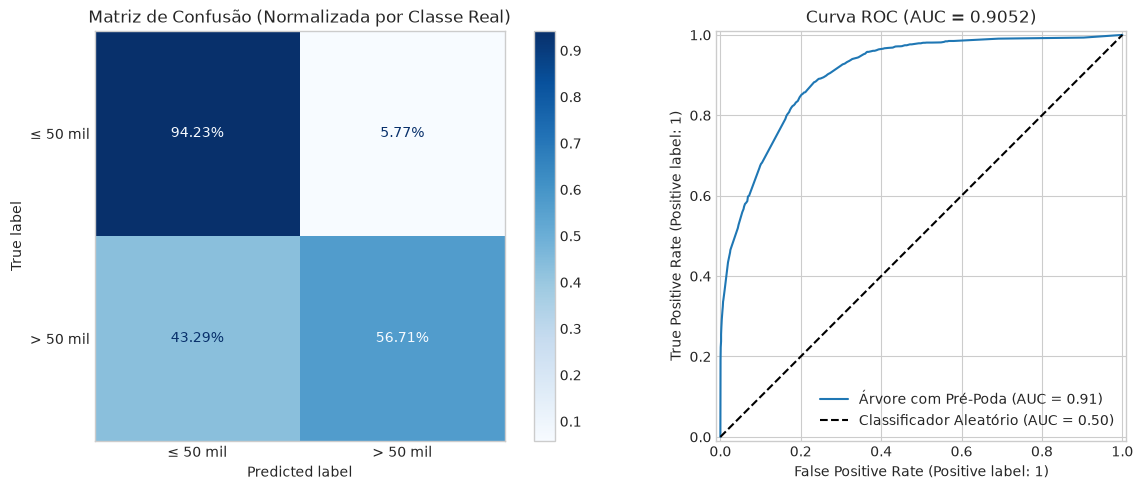

In [12]:
# Matriz de Confusão e Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Matriz de Confusão Normalizada
cm = confusion_matrix(y_test, y_pred, normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nomes_classes)
disp.plot(cmap="Blues", ax=axes[0], values_format=".2%")
axes[0].set_title("Matriz de Confusão (Normalizada por Classe Real)")
axes[0].grid(False)

# 2. Curva ROC
roc_disp = RocCurveDisplay.from_estimator(
    modelo_final,
    X_test,
    y_test,
    name="Árvore com Pré-Poda",
    ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], "k--", label="Classificador Aleatório (AUC = 0.50)")
axes[1].set_title(f"Curva ROC (AUC = {roc_auc_score(y_test, y_proba):.4f})")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


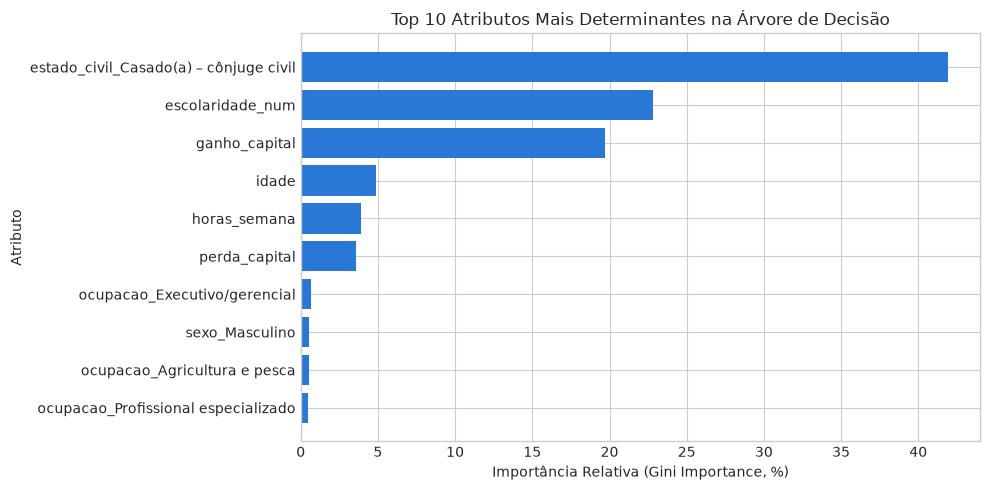

Top 5 atributos que definiram a divisão:
 1º estado_civil_Casado(a) – cônjuge civil: 41.90%
 2º escolaridade_num: 22.83%
 3º ganho_capital: 19.72%
 4º idade: 4.88%
 5º horas_semana: 3.88%


In [13]:
# Importância das Variáveis (Feature Importances)
importancias = pd.Series(modelo_final.feature_importances_, index=X_train.columns)
top_features = importancias[importancias > 0].sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(top_features.index[::-1], top_features.values[::-1] * 100, color="#2a78d6")
plt.title("Top 10 Atributos Mais Determinantes na Árvore de Decisão")
plt.xlabel("Importância Relativa (Gini Importance, %)")
plt.ylabel("Atributo")
plt.show()

print("Top 5 atributos que definiram a divisão:")
for rank, (feat, val) in enumerate(top_features.head(5).items(), 1):
    print(f" {rank}º {feat}: {val*100:.2f}%")

## 8. Persistência e Salvamento do Modelo Final em Disco

Para que o modelo final possa ser colocado em produção, consumido por APIs ou recarregado para novas predições sem necessidade de re-treinamento, salvamos os artefatos serializados no diretório `modelos/`:
1. `modelo_final_arvore.joblib`: O estimador Scikit-Learn serializado.
2. `artefato_completo.joblib`: Dicionário empacotado contendo o modelo, a lista de atributos de entrada na ordem exata do treinamento, os nomes das classes e as métricas de teste.


In [14]:
# Criação do diretório de modelos
DIRETORIO_MODELOS = "modelos"
os.makedirs(DIRETORIO_MODELOS, exist_ok=True)

caminho_modelo = os.path.join(DIRETORIO_MODELOS, "modelo_final_arvore.joblib")
caminho_artefato = os.path.join(DIRETORIO_MODELOS, "artefato_completo.joblib")

# 1. Salvamento do modelo Scikit-Learn
joblib.dump(modelo_final, caminho_modelo, compress=3)

# 2. Salvamento do artefato integrado com metadados para inferência segura
artefato_completo = {
    "modelo": modelo_final,
    "feature_names": list(X_train.columns),
    "classes": nomes_classes,
    "melhores_parametros": grid_busca.best_params_,
    "metricas_teste": {
        "acuracia": float(accuracy_score(y_test, y_pred)),
        "acuracia_balanceada": float(balanced_accuracy_score(y_test, y_pred)),
        "f1_score": float(f1_score(y_test, y_pred)),
        "roc_auc": float(roc_auc_score(y_test, y_proba))
    }
}
joblib.dump(artefato_completo, caminho_artefato, compress=3)

print("=" * 65)
print("ARTEFATOS DO MODELO SALVOS COM SUCESSO:")
print(f" -> Modelo Scikit-Learn:    {caminho_modelo} ({os.path.getsize(caminho_modelo)/1024:.2f} KB)")
print(f" -> Artefato com Metadados: {caminho_artefato} ({os.path.getsize(caminho_artefato)/1024:.2f} KB)")
print("=" * 65)


ARTEFATOS DO MODELO SALVOS COM SUCESSO:
 -> Modelo Scikit-Learn:    modelos/modelo_final_arvore.joblib (10.16 KB)
 -> Artefato com Metadados: modelos/artefato_completo.joblib (10.37 KB)


In [15]:
# Demonstração de Carregamento e Inferência com o Modelo Salvo (Sanity Check)
modelo_carregado = joblib.load(caminho_modelo)

# Realizando predição em uma amostra real do conjunto de teste
amostra = X_test.iloc[[0]]
pred_classe = modelo_carregado.predict(amostra)[0]
pred_prob = modelo_carregado.predict_proba(amostra)[0]

print("Teste de Inferência com o Modelo Carregado do Disco:")
print(f" -> Classe Predita:        {nomes_classes[pred_classe]}")
print(f" -> Probabilidade (≤ 50 mil): {pred_prob[0]*100:.2f}%")
print(f" -> Probabilidade (> 50 mil): {pred_prob[1]*100:.2f}%")
print(f" -> Classe Real do Teste:  {nomes_classes[y_test.iloc[0]]}")
print("Verificação concluída: Modelo 100% operacional para produção!")


Teste de Inferência com o Modelo Carregado do Disco:
 -> Classe Predita:        ≤ 50 mil
 -> Probabilidade (≤ 50 mil): 99.89%
 -> Probabilidade (> 50 mil): 0.11%
 -> Classe Real do Teste:  ≤ 50 mil
Verificação concluída: Modelo 100% operacional para produção!


## 9. Extração e Interpretação de Regras Semânticas (XAI)

As Árvores de Decisão são modelos da classe *White-Box*. Podemos percorrer seus caminhos internos da raiz até cada nó-folha para extrair **Regras de Decisão Explicáveis (if-then)**.

> **Mapeamento Auditável:**
> O alvo foi codificado explicitamente como 0/1 na seção 2, de modo que `modelo_final.classes_` é `[0, 1]` e `nomes_classes[0]`/`[1]` correspondem a `≤ 50 mil`/`> 50 mil`. (No notebook anterior de avaliação, o alvo textual era ordenado alfabeticamente pelo scikit-learn, o que invertia os rótulos das regras.)
>
> As regras são simplificadas antes da leitura: quando um mesmo atributo aparece várias vezes no caminho (por exemplo, três cortes sucessivos em `ganho_capital`), só o corte mais restritivo de cada direção é mantido. Os perfis são ordenados pelo número de pessoas do treino que cobrem, entre as folhas com ao menos 90% de pureza, para evitar que folhas de poucas amostras apareçam como perfis principais.


In [16]:
def simplificar_condicoes(caminho):
    """Mantém, para cada atributo, só o corte mais restritivo em cada direção (<= menor valor, > maior valor)."""
    limites = {}
    for feature, op, valor in caminho:
        chave = (feature, op)
        if chave not in limites:
            limites[chave] = valor
        elif op == "<=":
            limites[chave] = min(limites[chave], valor)
        else:
            limites[chave] = max(limites[chave], valor)
    ordem = []
    for feature, op, _ in caminho:
        if (feature, op) not in ordem:
            ordem.append((feature, op))
    return [(f, op, limites[(f, op)]) for f, op in ordem]


def extrair_regras(arvore, feature_names, class_names):
    """Extrai as regras de decisão de todos os nós-folha, com o mapeamento de classes via `classes_`."""
    tree = arvore.tree_
    # posição de cada classe em tree.value segue arvore.classes_ (aqui [0, 1])
    nome_por_indice = {i: class_names[int(cls)] for i, cls in enumerate(arvore.classes_)}
    regras = []

    def percorrer(no, caminho):
        if tree.feature[no] != _tree.TREE_UNDEFINED:
            feature = feature_names[tree.feature[no]]
            threshold = tree.threshold[no]
            percorrer(tree.children_left[no], caminho + [(feature, "<=", threshold)])
            percorrer(tree.children_right[no], caminho + [(feature, ">", threshold)])
        else:
            valores_classes = tree.value[no][0]
            idx_classe_vencedora = int(valores_classes.argmax())
            total_amostras = int(tree.n_node_samples[no])
            pureza = (valores_classes.max() / valores_classes.sum()) * 100
            condicoes = simplificar_condicoes(caminho)
            regras.append({
                "Classe": nome_por_indice[idx_classe_vencedora],
                "Amostras": total_amostras,
                "Cobertura (%)": round(total_amostras / tree.n_node_samples[0] * 100, 2),
                "Probabilidade (%)": round(pureza, 2),
                "Regra": " AND ".join(f"{f} {op} {v:.2f}" for f, op, v in condicoes),
                "condicoes": condicoes,
            })

    percorrer(0, [])
    return pd.DataFrame(regras)


df_regras = extrair_regras(modelo_final, list(X_train.columns), nomes_classes)
print(f"Total de regras (folhas) geradas na árvore com pré-poda: {len(df_regras)}")
display(df_regras.drop(columns="condicoes").head(6))

Total de regras (folhas) geradas na árvore com pré-poda: 140


,Classe,Amostras,Cobertura (%),Probabilidade (%),Regra
0,≤ 50 mil,3498,16.58,99.89,estado_civil_Casado(a) – cônjuge civil <= 0.50...
1,≤ 50 mil,74,0.35,98.65,estado_civil_Casado(a) – cônjuge civil <= 0.50...
2,≤ 50 mil,73,0.35,100.00,estado_civil_Casado(a) – cônjuge civil <= 0.50...
3,≤ 50 mil,53,0.25,96.23,estado_civil_Casado(a) – cônjuge civil <= 0.50...
4,≤ 50 mil,280,1.33,100.00,estado_civil_Casado(a) – cônjuge civil <= 0.50...
5,≤ 50 mil,56,0.27,94.64,estado_civil_Casado(a) – cônjuge civil <= 0.50...


In [17]:
def _fmt(v):
    return f"{v:,.0f}".replace(",", ".")


def interpretar_condicao(feature, op, valor):
    """Converte uma condição da árvore em linguagem natural, citando o limiar real do corte."""
    maior = op == ">"
    if feature == "ganho_capital":
        return f"ganho de capital acima de US$ {_fmt(valor)}" if maior else f"ganho de capital de até US$ {_fmt(valor)}"
    if feature == "perda_capital":
        return f"perda de capital acima de US$ {_fmt(valor)}" if maior else f"perda de capital de até US$ {_fmt(valor)}"
    if feature == "escolaridade_num":
        nivel = int(np.floor(valor)) if not maior else int(np.ceil(valor))
        return f"escolaridade de nível {nivel} ou superior" if maior else f"escolaridade até o nível {nivel}"
    if feature == "horas_semana":
        return f"mais de {valor:.0f} horas semanais" if maior else f"até {valor:.0f} horas semanais"
    if feature == "idade":
        return f"mais de {valor:.0f} anos" if maior else f"até {valor:.0f} anos"
    # dummies: nome_coluna_valor (one-hot) -> "> 0.5" significa que a categoria está presente
    for prefixo, rotulo_pt in [("estado_civil_", "estado civil"), ("ocupacao_", "ocupação"),
                               ("relacao_familiar_", "relação familiar"), ("classe_trabalho_", "classe de trabalho"),
                               ("sexo_", "sexo"), ("raca_", "raça"), ("pais_origem_", "país de origem")]:
        if feature.startswith(prefixo):
            categoria = feature[len(prefixo):]
            return f"{rotulo_pt} = {categoria}" if maior else f"{rotulo_pt} ≠ {categoria}"
    return f"{feature} {op} {valor:.2f}"


def interpretar_regra(condicoes):
    """Frase em linguagem natural a partir da lista de condições (feature, op, valor)."""
    partes = [interpretar_condicao(f, op, v) for f, op, v in condicoes]
    return "Pessoas com " + "; ".join(partes) + "."


def mostrar_perfis(df_regras, classe, n=3, pureza_minima=90):
    """Perfis da classe ordenados pela cobertura, entre as folhas com pureza >= pureza_minima."""
    sel = df_regras[(df_regras["Classe"] == classe) & (df_regras["Probabilidade (%)"] >= pureza_minima)]
    sel = sel.sort_values(["Amostras", "Probabilidade (%)"], ascending=False)
    print("=" * 70)
    print(f"PRINCIPAIS PERFIS DE {classe} (folhas com pureza ≥ {pureza_minima}%, ordenadas pela cobertura)")
    print("=" * 70)
    for idx, linha in sel.head(n).iterrows():
        print(f"\n[Folha {idx}] Pureza: {linha['Probabilidade (%)']}% | Amostras no Treino: {linha['Amostras']} "
              f"({linha['Cobertura (%)']}% do treino)")
        print(f" Regra Técnica: {linha['Regra']}")
        print(f" Leitura: {interpretar_regra(linha['condicoes'])}")
    return sel.head(n)

print("Funções de interpretação registradas.")

Funções de interpretação registradas.


In [18]:
# Perfis de Alta Renda (> 50 mil)
perfis_alta = mostrar_perfis(df_regras, "> 50 mil", n=3)

PRINCIPAIS PERFIS DE > 50 mil (folhas com pureza ≥ 90%, ordenadas pela cobertura)

[Folha 138] Pureza: 100.0% | Amostras no Treino: 383 (1.82% do treino)
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil > 0.50 AND escolaridade_num > 12.50 AND ganho_capital > 5095.50 AND idade <= 58.50
 Leitura: Pessoas com estado civil = Casado(a) – cônjuge civil; escolaridade de nível 13 ou superior; ganho de capital acima de US$ 5.096; até 58 anos.

[Folha 114] Pureza: 100.0% | Amostras no Treino: 306 (1.45% do treino)
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil > 0.50 AND escolaridade_num <= 12.50 AND ganho_capital > 5095.50 AND idade <= 59.50
 Leitura: Pessoas com estado civil = Casado(a) – cônjuge civil; escolaridade até o nível 12; ganho de capital acima de US$ 5.096; até 60 anos.

[Folha 68] Pureza: 100.0% | Amostras no Treino: 144 (0.68% do treino)
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil <= 0.50 AND ganho_capital > 7073.50 AND escolaridade_num > 10.50
 Leitura: P

In [19]:
# Perfis de Baixa Renda (≤ 50 mil)
perfis_baixa = mostrar_perfis(df_regras, "≤ 50 mil", n=3)

PRINCIPAIS PERFIS DE ≤ 50 mil (folhas com pureza ≥ 90%, ordenadas pela cobertura)

[Folha 0] Pureza: 99.89% | Amostras no Treino: 3498 (16.58% do treino)
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil <= 0.50 AND ganho_capital <= 7073.50 AND escolaridade_num <= 11.50 AND perda_capital <= 1990.50 AND horas_semana <= 40.50 AND idade <= 33.50 AND ocupacao_Serviços de proteção <= 0.50 AND ocupacao_Ofícios e reparos <= 0.50 AND classe_trabalho_Autônomo (não incorporado) <= 0.50
 Leitura: Pessoas com estado civil ≠ Casado(a) – cônjuge civil; ganho de capital de até US$ 7.074; escolaridade até o nível 11; perda de capital de até US$ 1.990; até 40 horas semanais; até 34 anos; ocupação ≠ Serviços de proteção; ocupação ≠ Ofícios e reparos; classe de trabalho ≠ Autônomo (não incorporado).

[Folha 10] Pureza: 98.85% | Amostras no Treino: 1742 (8.26% do treino)
 Regra Técnica: estado_civil_Casado(a) – cônjuge civil <= 0.50 AND ganho_capital <= 7073.50 AND escolaridade_num <= 12.50 AND perda

## 10. Conclusões

### Principais Achados:
1. **Higienização de Features:** A exclusão de `peso_amostral` (`fnlwgt`) e a unificação da escolaridade em `escolaridade_num` não alteram o desempenho da árvore (83,95% × 83,96% de acurácia na validação cruzada), mas eliminam cortes sem significado individual das regras e simplificam o espaço de busca.
2. **Impacto do Desbalanceamento:** `class_weight='balanced'` eleva a revocação da classe `> 50 mil` de 50% para 86%, ao custo de 6 pontos de acurácia (83,96% → 77,81%). Como o objetivo da atividade é maximizar o acerto, o balanceamento foi incluído na grade e **não foi selecionado**: o melhor candidato por acurácia usa `class_weight=None`, enquanto o melhor por F1 (68,4%) usa `balanced` com 80,2% de acurácia.
3. **Pré-Poda Clássica:** A grade ampliada (280 candidatos; `max_depth` de 4 a 12, cobrindo a profundidade 10 indicada pela curva de validação) selecionou `max_depth=10`, `min_samples_leaf=50`, `min_samples_split=2`, com **84,93% de acurácia na validação cruzada** e **84,88% no teste** (ROC-AUC 0,900; revocação de `> 50 mil` 56,7%). A árvore original (`max_depth=7`, selecionada por F1 em uma grade menor) obteve 85,31% no teste. A diferença entre as duas está dentro da incerteza do conjunto de teste (erro padrão de cerca de 0,4 ponto percentual), o que indica que **a árvore de decisão satura em torno de 85% de acurácia** nesta base, qualquer que seja a estratégia de pré-poda. Ganhos além desse patamar exigem outras famílias de modelos (notebook 04).
4. **Persistência do Modelo:** O modelo foi exportado em `modelos/modelo_final_arvore.joblib` (pasta ignorada pelo git), acompanhado de dicionário com nomes de colunas, hiperparâmetros e métricas de teste.
5. **Interpretabilidade (XAI):** Com o mapeamento de classes verificado por `classes_`, os perfis de alta renda com maior cobertura combinam `Casado(a) – cônjuge civil` com ganho de capital acima de US$ 5.096 (pureza de 100%, mas cobrindo só 1,8% e 1,5% do treino). O perfil de baixa renda mais amplo cobre 16,6% do treino com 99,9% de pureza: pessoas não casadas, sem ganho de capital relevante, escolaridade até o nível 11, jornada de até 40 horas e idade até 33 anos. As regras extraídas são longas (até 10 condições) porque a árvore selecionada tem 140 folhas; os perfis de alta renda com alta pureza dependem quase sempre de ganho de capital, variável positiva para só 8% das pessoas.
